# IMDB Sentiment Classification

**Revised from four original BSc notebooks.** Reproducible comparison of Naïve Bayes and SVM with two tokenization strategies. This revision fixes TF-IDF leakage, evaluates only on held-out test data, uses continuous scores for ROC AUC, and keeps sparse matrices. **Results must be regenerated; historical scores are not directly comparable.**

Run from the project directory with `IMDB Dataset.csv` available. Dataset is in the original project files.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

DATA_PATH = Path('IMDB Dataset.csv')
df = pd.read_csv(DATA_PATH)
assert {'review','sentiment'}.issubset(df.columns)
df = df.dropna(subset=['review','sentiment']).copy()
df['sentiment'] = df['sentiment'].map({'negative': 0, 'positive': 1})
assert df['sentiment'].notna().all(), 'Unexpected labels'
print('Dataset:', df.shape, '\n', df['sentiment'].value_counts())

Dataset: (50000, 2) 
 sentiment
1    25000
0    25000
Name: count, dtype: int64


## Hold-out split before vectorizer fitting
Use the same stratified split for every model. Each pipeline learns vocabulary/IDF exclusively on the training partition.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df['review'], df['sentiment'].astype(int), test_size=0.2,
    stratify=df['sentiment'], random_state=42)
print(len(X_train), len(X_test))

40000 10000


In [ ]:
def clean_text(text):
    text = BeautifulSoup(str(text), 'html.parser').get_text(' ')
    return re.sub(r'[^a-zA-Z\s]', ' ', text).lower()

def split_tokens(text):
    return text.split()

# NLTK's TreebankWordTokenizer needs no runtime corpus downloads.
from nltk.tokenize import TreebankWordTokenizer
_tokenizer = TreebankWordTokenizer()
def nltk_tokens(text):
    return _tokenizer.tokenize(text)

# Both branches share the same cleaning; only tokenization differs.
# No stemming/stopword removal in this revised baseline, so comparison
TOKENIZERS = {'split': split_tokens, 'nltk_treebank': nltk_tokens}

In [5]:
from sklearn.base import clone
rows = []
models = {}
for tok_name, tokenizer in TOKENIZERS.items():
    for model_name, estimator in [('MultinomialNB', MultinomialNB()),
                                  ('LinearSVC', LinearSVC(random_state=42))]:
        pipe = Pipeline([
            ('tfidf', TfidfVectorizer(preprocessor=clean_text,
                                     tokenizer=tokenizer, token_pattern=None,
                                     lowercase=False, max_features=5000)),
            ('model', clone(estimator))
        ])
        pipe.fit(X_train, y_train)
        predictions = pipe.predict(X_test)
        scores = (pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba')
                  else pipe.decision_function(X_test))
        rows.append({'tokenizer': tok_name, 'model': model_name,
                     'test_accuracy': accuracy_score(y_test, predictions),
                     'test_f1': f1_score(y_test, predictions),
                     'test_roc_auc': roc_auc_score(y_test, scores)})
        models[(tok_name, model_name)] = pipe
        print(f'\n{tok_name} / {model_name}\n', classification_report(y_test, predictions))
results = pd.DataFrame(rows).sort_values('test_f1', ascending=False)
display(results)
results.to_csv('model_comparison.csv', index=False)


split / MultinomialNB
               precision    recall  f1-score   support

           0       0.86      0.85      0.85      5000
           1       0.85      0.86      0.85      5000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000


split / LinearSVC
               precision    recall  f1-score   support

           0       0.89      0.88      0.89      5000
           1       0.89      0.90      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000


nltk_treebank / MultinomialNB
               precision    recall  f1-score   support

           0       0.86      0.85      0.85      5000
           1       0.85      0.86      0.85      5000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     1000

,tokenizer,model,test_accuracy,test_f1,test_roc_auc
1,split,LinearSVC,0.8897,0.890369,0.957604
3,nltk_treebank,LinearSVC,0.8896,0.890258,0.957537
0,split,MultinomialNB,0.8545,0.854950,0.928244
2,nltk_treebank,MultinomialNB,0.8541,0.854580,0.928130


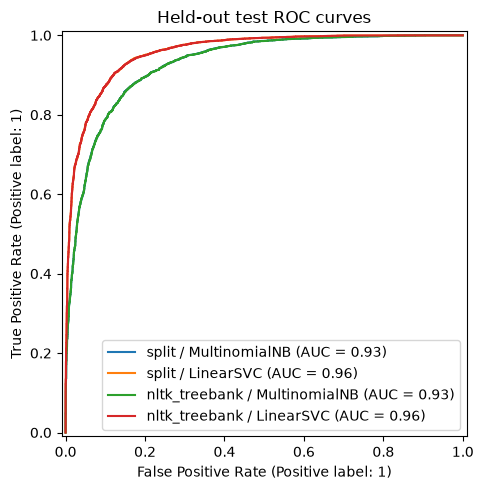

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
for (tok_name, model_name), pipe in models.items():
    score = (pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, 'predict_proba')
             else pipe.decision_function(X_test))
    RocCurveDisplay.from_predictions(y_test, score, ax=ax,
                                      name=f'{tok_name} / {model_name}')
ax.set_title('Held-out test ROC curves')
plt.tight_layout()
plt.savefig('test_roc_curves.png', dpi=160)
plt.show()

## Limitations and research extension

- This compares `LinearSVC`, **not** the RBF `SVC` in the original notebooks; it is a more practical sparse-text baseline. Do not describe results as an exact reproduction.
- Text preprocessing choices may discard useful punctuation and domain-specific information.

